# Comparare performanță pe testul din alt set de date

**1. Încărcare dataset**

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Model de clasificare a imaginilor OCT folosind MobileNetV2

**1. Încărcare model**

In [2]:
from tensorflow.keras.models import load_model

# Încarcă modelul Keras
model_keras = load_model("/content/oct_cnn_model_MobileNetV2.h5")
model_keras.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,110 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2 (12.00 B)

**2. Testare**

In [25]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import tensorflow as tf


# Parametri
BATCH_SIZE = 32
class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

# Functia de preprocesare
import cv2

TARGET_SIZE = (224, 224)
def preprocess_oct(image):
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, TARGET_SIZE)
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8) if image.max() <= 1.0 else image.astype(np.uint8)
    image = cv2.medianBlur(image, 3)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    image = clahe.apply(image)
    image = image.astype("float32") / 255.0
    return np.stack([image, image, image], axis=-1)


# Creeaza lista cu imagini si etichete
ROOT = "/content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset"
class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]
VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

paths = []
labels = []

for idx, cls in enumerate(class_names):
    folder = os.path.join(ROOT, cls)
    print(f"Scanning folder: {folder}")

    for root_dir, _, files in os.walk(folder):
        for fname in files:
            if fname.lower().endswith(VALID_EXT):
                paths.append(os.path.join(root_dir, fname))
                labels.append(idx)

labels = np.array(labels)
print(f"Total images found: {len(paths)}")

# Batch-by-batch predict
keras_preds = []

for i in tqdm(range(0, len(paths), BATCH_SIZE), desc="Predicting batches"):
    batch_paths = paths[i:i+BATCH_SIZE]
    X_batch = []
    for p in batch_paths:
        img = tf.keras.utils.load_img(p, target_size=TARGET_SIZE)
        img = tf.keras.utils.img_to_array(img)
        img = preprocess_oct(img)
        X_batch.append(img)
    X_batch = np.array(X_batch)
    preds = np.argmax(model_keras.predict(X_batch, verbose=0), axis=1)
    keras_preds.extend(preds)

keras_preds = np.array(keras_preds)



Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/CNV
Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/DME
Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/DRUSEN
Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/NORMAL
Total images found: 3571


Predicting batches: 100%|██████████| 112/112 [03:35<00:00,  1.92s/it]


**3. Afișare rezultate**

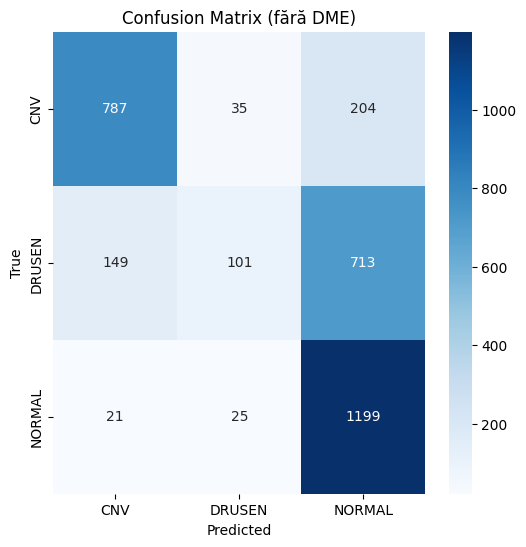


=== Acuratețe per clasă (fără DME) ===
CNV: 0.7671
DRUSEN: 0.1049
NORMAL: 0.9631

Classification Report (fără DME):

              precision    recall  f1-score   support

         CNV       0.82      0.68      0.75      1152
      DRUSEN       0.63      0.10      0.17      1042
      NORMAL       0.57      0.87      0.69      1376

   micro avg       0.65      0.58      0.61      3570
   macro avg       0.67      0.55      0.53      3570
weighted avg       0.67      0.58      0.55      3570

Test Accuracy (fără DME): 58.46%


In [27]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Indici clase
keep_idx = [0, 2, 3]
class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]

# Matrice confuzie pe toate clasele
cm_full = confusion_matrix(labels, keras_preds, labels=[0,1,2,3])

# Matrice confuzie filtrată
cm_filtered = cm_full[np.ix_(keep_idx, keep_idx)]

plt.figure(figsize=(6,6))
sns.heatmap(cm_filtered, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered, yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()

# Acuratețe per clasă
class_acc_filtered = cm_filtered.diagonal() / cm_filtered.sum(axis=1)
print("\n=== Acuratețe per clasă  ===")
for cls, acc in zip(class_names_filtered, class_acc_filtered):
    print(f"{cls}: {acc:.4f}")

# Raport
y_true_filtered = labels[np.isin(labels, keep_idx)]
y_pred_filtered = keras_preds[np.isin(labels, keep_idx)]

report_filtered = classification_report(
    y_true_filtered,
    y_pred_filtered,
    labels=keep_idx,
    target_names=class_names_filtered
)

print("\nClassification Report :\n")
print(report_filtered)

# Acuratețe globală
acc_total_filtered = accuracy_score(y_true_filtered, y_pred_filtered)
print(f"Test Accuracy : {acc_total_filtered*100:.2f}%")


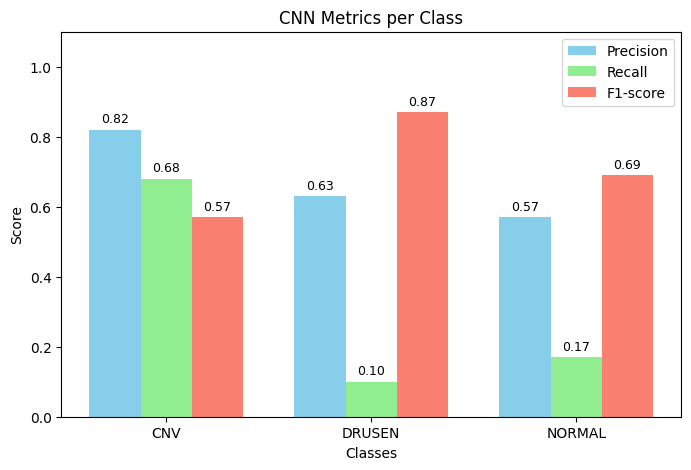

In [32]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV",  "DRUSEN", "NORMAL"]

precision = [0.82,  0.63, 0.57]
recall    = [0.68,  0.10, 0.17]
f1_score  = [0.57,  0.87, 0.69]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

# Afișez scorurile
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()


# Model de clasificare a imaginilor OCT folosind ResNet18

**1. Încărcare model**

In [3]:
import torch
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pt_model = torch.load(
    '/content/oct_cnn_model_ResNet18.pth',
    map_location=device,
    weights_only=False
)

pt_model.eval()


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

**2. Testare**

In [29]:
import torch
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Parametri
BATCH_SIZE = 32
class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Dataset PyTorch
class OCTDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = self.labels[idx]
        return img, label


# Creez dataset și dataloader
from torchvision import transforms

transform_pt = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

dataset_pt = OCTDataset(paths, labels, transform=transform_pt)
dataloader_pt = DataLoader(dataset_pt, batch_size=BATCH_SIZE, shuffle=False)



# Predict batch-by-batch
pt_model.to(DEVICE)
pt_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, lbls in tqdm(dataloader_pt, desc="Predicting PyTorch batches"):
        imgs = imgs.to(DEVICE)
        outputs = pt_model(imgs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)



Predicting PyTorch batches: 100%|██████████| 112/112 [05:59<00:00,  3.21s/it]


**3. Afișare rezultate**

Test Accuracy (fără DME): 74.06%


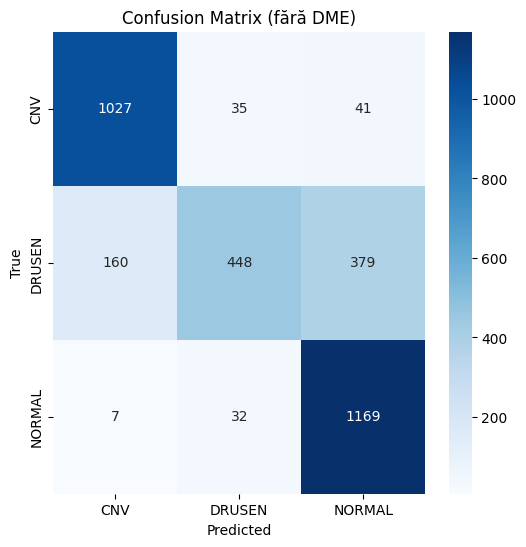


Classification Report (fără DME):

              precision    recall  f1-score   support

         CNV       0.86      0.89      0.88      1152
      DRUSEN       0.87      0.43      0.58      1042
      NORMAL       0.74      0.85      0.79      1376

   micro avg       0.80      0.74      0.77      3570
   macro avg       0.82      0.72      0.75      3570
weighted avg       0.82      0.74      0.75      3570


=== Acuratețe per clasă (fără DME) ===
CNV: 0.9311
DRUSEN: 0.4539
NORMAL: 0.9677


In [31]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Indici clase păstrate
keep_idx = [0, 2, 3]
class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]

# Filtrez valorile
all_labels_filtered = all_labels[np.isin(all_labels, keep_idx)]
all_preds_filtered  = all_preds[np.isin(all_labels, keep_idx)]

# Acuratețe globală
acc_total_filtered = accuracy_score(all_labels_filtered, all_preds_filtered)
print(f"Test Accuracy : {acc_total_filtered*100:.2f}%")

# Matrice confuzie
cm_filtered = confusion_matrix(all_labels_filtered, all_preds_filtered, labels=keep_idx)
plt.figure(figsize=(6,6))
sns.heatmap(cm_filtered, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered, yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()

# Raport clasificare
report_filtered = classification_report(all_labels_filtered, all_preds_filtered, labels=keep_idx, target_names=class_names_filtered)
print("\nClassification Report:\n")
print(report_filtered)

# Acuratețe per clasă
class_acc_filtered = cm_filtered.diagonal() / cm_filtered.sum(axis=1)
print("\n=== Acuratețe per clasă  ===")
for cls, acc in zip(class_names_filtered, class_acc_filtered):
    print(f"{cls}: {acc:.4f}")


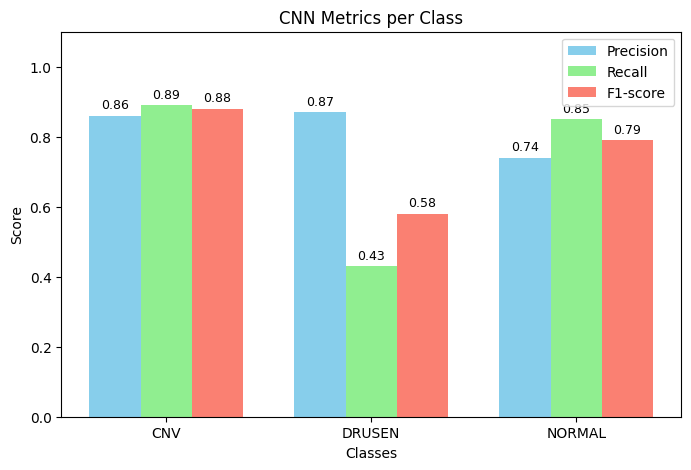

In [33]:
import matplotlib.pyplot as plt
import numpy as np

classes = ["CNV",  "DRUSEN", "NORMAL"]

precision = [0.86,  0.87, 0.74]
recall    = [0.89,  0.43, 0.85]
f1_score  = [0.88,  0.58, 0.79]

x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='skyblue')
rects2 = ax.bar(x, recall, width, label='Recall', color='lightgreen')
rects3 = ax.bar(x + width, f1_score, width, label='F1-score', color='salmon')

ax.set_ylabel('Score')
ax.set_xlabel('Classes')
ax.set_title('CNN Metrics per Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0,1.1)
ax.legend()

# Afișez scorurile
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width()/2, height),
                    xytext=(0,3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.show()
